# ResolVI to address noise and biases in spatial transcriptomics
In this tutorial, we go through the steps of training resolVI for correction in cellular-resolved spatial transcriptomics. This addresses erroneous co-expression pattern after cellular segmentation as well as unspecific background in these technologies. We highly recommend to optimize cell segmentation before running resolVI as a better cell segmentation will also yield better downstream results and both steps are complementary.

Plan for this tutorial:

1. Loading the data
2. Training an unsupervised and (semi-)supervised resolVI model
3. Visualizing the latent space
4. Transfer mapping.
5. Generating corrected counts and perform DE analysis

```{note}
Running the following cell will install tutorial dependencies on Google Colab only. It will have no effect on environments other than Google Colab.
```

In [1]:
import sys

if "google.colab" in sys.modules:
    !pip install --quiet scvi-colab
    from scvi_colab import install

    install(for_tutorials=False)
    !pip install --quiet "scviva-tools[tutorials]"
    !pip install --quiet decoupler
    !pip install --quiet adjustText

In [2]:
import os
import tempfile

import decoupler as dc
import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc
import scvi
import scviva
from scviva.model import ResolVI

In [3]:
HAS_RSC = False
try:
    import cupy as cp
    import rapids_singlecell as rsc

    # rapids_singlecell can be importable without a usable GPU (e.g. a CPU runtime on Google Colab)
    HAS_RSC = cp.cuda.runtime.getDeviceCount() > 0
except Exception:  # ImportError, or a CUDA error when no GPU/driver is present
    HAS_RSC = False

if HAS_RSC:
    print("RAPIDS SingleCell is installed and a GPU is available, using rapids_singlecell")
else:
    print("RAPIDS SingleCell (or a GPU) is not available, falling back to scanpy")

RAPIDS SingleCell is installed and a GPU is available, using rapids_singlecell


In [4]:
sc.set_figure_params(figsize=(4, 4))
save_dir = tempfile.TemporaryDirectory()
%config InlineBackend.print_figure_kwargs={'facecolor' : "w"}
%config InlineBackend.figure_format='retina'

scviva.settings.seed = 0
print("Last run with scviva-tools version:", scviva.__version__)

Seed set to 0


Last run with scviva-tools version: 0.1.8


In [5]:
scvi.settings.seed = 0
print("Last run with scvi-tools version:", scvi.__version__)

Seed set to 0


Last run with scvi-tools version: 1.5.1


## Data Loading

For the purposes of this notebook, we will be loading a Xenium dataset of a mouse brain. We will use the left hemisphere for model training and the right hemisphere for transfer mapping.
The data was originally labeled using Leiden clustering of an optimized segmentation using the [ProSeg](https://www.biorxiv.org/content/10.1101/2024.04.25.591218v1) algorithm, which is a scalable algorithm for transcriptome-informed segmentation.

In [6]:
adata_path = os.path.join(save_dir.name, "tutorial_xenium_brain.h5ad")
adata = sc.read(
    adata_path, backup_url="https://exampledata.scverse.org/scvi-tools/tutorial_xenium_brain.h5ad"
)
adata

  0%|          | 0.00/170M [00:00<?, ?B/s]

AnnData object with n_obs × n_vars = 130604 × 248
    obs: 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'fov', 'predicted_celltype'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'log1p'
    obsm: 'X_resolvi_transferred', 'X_spatial', 'X_umap_transferred'
    layers: 'counts', None (.X)

We computed a UMAP after transfering labels using the ProSeg segmented dataset and the UMAP serves as ground truth.

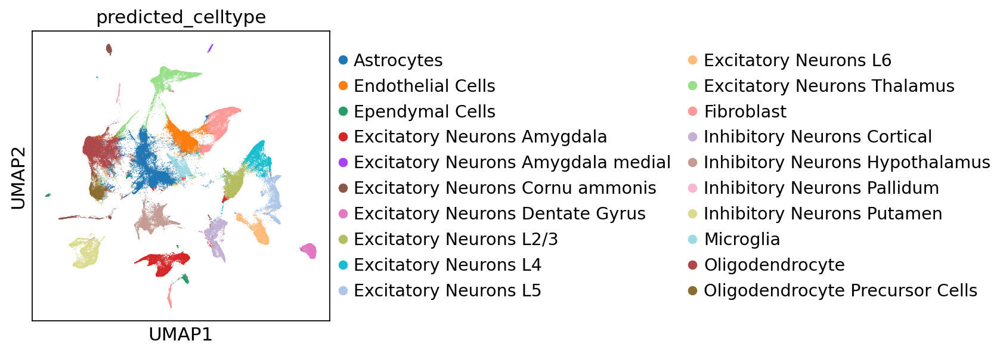

/tmp/ipykernel_3603058/1077018278.py:3: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata, color="predicted_celltype", spot_size=30)


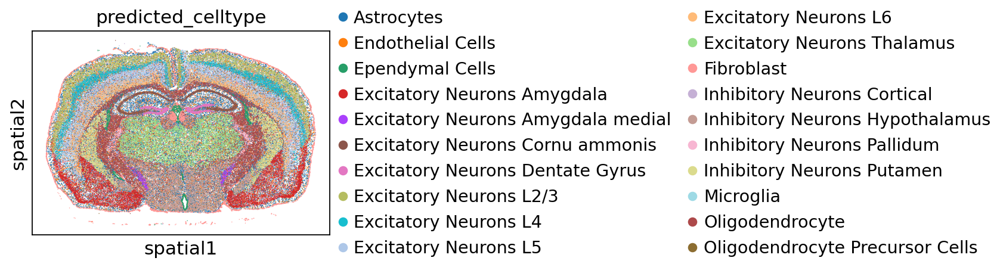

In [7]:
adata.obsm["X_umap"] = adata.obsm["X_umap_transferred"]
sc.pl.umap(adata, color="predicted_celltype")
sc.pl.spatial(adata, color="predicted_celltype", spot_size=30)

In [8]:
adata.obs["predicted_celltype"].value_counts()

predicted_celltype
Astrocytes                            17315
Oligodendrocyte                       14567
Fibroblast                            10070
Endothelial Cells                      9775
Inhibitory Neurons Hypothalamus        9284
Excitatory Neurons Amygdala            8640
Excitatory Neurons Thalamus            7947
Excitatory Neurons L5                  7004
Excitatory Neurons L2/3                6393
Inhibitory Neurons Putamen             5753
Inhibitory Neurons Cortical            5711
Excitatory Neurons L4                  5500
Excitatory Neurons L6                  5052
Microglia                              4141
Oligodendrocyte Precursor Cells        3872
Excitatory Neurons Dentate Gyrus       3283
Excitatory Neurons Cornu ammonis       2787
Ependymal Cells                        2202
Inhibitory Neurons Pallidum             658
Excitatory Neurons Amygdala medial      650
Name: count, dtype: int64

We use this dataset to set up a semisupervised and an unsupervised model in resolVI and train these. We split the dataset into right and left hemisphere to demonstrate query mapping.

/tmp/ipykernel_3603058/1090802531.py:2: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata, color="hemisphere", spot_size=30)
... storing 'hemisphere' as categorical


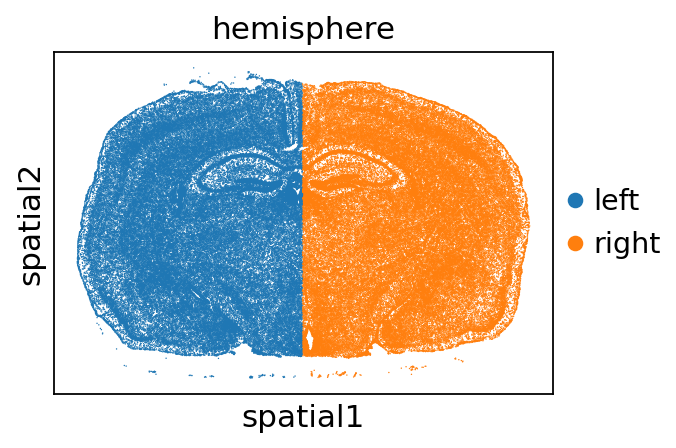

In [9]:
adata.obs["hemisphere"] = ["right" if x > 5000 else "left" for x in adata.obsm["X_spatial"][:, 0]]
sc.pl.spatial(adata, color="hemisphere", spot_size=30)

In [10]:
ref_adata = adata[adata.obs["hemisphere"] == "left"].copy()
query_adata = adata[adata.obs["hemisphere"] == "right"].copy()

## Train resolVI model

As in the scANVI notebook, we need to register the AnnData object for use in resolVI. Namely, we can ignore the batch parameter because those cells don't have much batch effect to begin with as they are derived from a single slice. However, we will give the celltype labels for resolVI to use. Setting up AnnData computes spatial neighbors within each batch. This step might take minutes for very large datasets. It is important that different slices are used as batch covariate.

In [11]:
ResolVI.setup_anndata(ref_adata, labels_key="predicted_celltype", layer="counts")

Preparing data for training. This may take a while. RAPIDS SingleCell will be used if installed.
INFO     Generating sequential column names                                                                        
INFO     Generating sequential column names                                                                        


/home/access/PycharmProjects/scvi-tools/src/scvi/data/fields/_dataframe_field.py:187: UserWarning: Category 0 in adata.obs['_scvi_ind_x'] has fewer than 3 cells. Models may not train properly.
  categorical_mapping = _make_column_categorical(


In [12]:
supervised_resolvi = ResolVI(ref_adata, semisupervised=True)

We use here only 20 epochs to speed up running the tutorial. We would recommend using 100 epochs here.

In [13]:
supervised_resolvi.train(max_epochs=50)

Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/home/access/miniconda3/lib/python3.13/site-packages/lightning/pytorch/trainer/configuration_validator.py:68: You passed in a `val_dataloader` but have no `validation_step`. Skipping val loop.
You are using a CUDA device ('NVIDIA GeForce RTX 4090') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for perfor

Training:   0%|          | 0/50 [00:00<?, ?it/s]

/home/access/miniconda3/lib/python3.13/site-packages/scviva/module/_resolvae.py:382: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  concentration=torch.tensor(
2026-11-16 10:31:00 | [INFO] Guessed max_plate_nesting = 2
`Trainer.fit` stopped: `max_epochs=50` reached.


Now we can predict the cell type labels using the trained model, and get the latent space.
ResolVI uses pyro. Pyro stores parameters in a pyro_param_store. It is necessary that only a single model is used at a time, e.g. after query training only the query model is valid and the reference model gets overwritten.

In [14]:
ref_adata

AnnData object with n_obs × n_vars = 66457 × 248
    obs: 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'fov', 'predicted_celltype', 'hemisphere', '_indices', '_scvi_batch', '_scvi_ind_x', '_scvi_labels'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'log1p', 'predicted_celltype_colors', 'hemisphere_colors', '_resolvi_prepare_data_config', '_scvi_uuid', '_scvi_manager_uuid'
    obsm: 'X_resolvi_transferred', 'X_spatial', 'X_umap_transferred', 'X_umap', 'index_neighbor', 'distance_neighbor'
    layers: 'counts', None (.X)

In [15]:
ref_adata.obsm["resolvi_celltypes"] = supervised_resolvi.predict(
    ref_adata, num_samples=3, soft=True
)

Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.


Sampling local variables, batch:   0%|          | 0/133 [00:00<?, ?it/s]

In [16]:
ref_adata.obs["resolvi_predicted"] = ref_adata.obsm["resolvi_celltypes"].idxmax(axis=1)
ref_adata.obsm["X_resolVI"] = supervised_resolvi.get_latent_representation(ref_adata)

Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.


Again, we may visualize the latent space as well as the inferred labels

In [17]:
if HAS_RSC:
    rsc.pp.neighbors(ref_adata, use_rep="X_resolVI")
    rsc.tl.umap(ref_adata)
else:
    sc.pp.neighbors(ref_adata, use_rep="X_resolVI")
    sc.tl.umap(ref_adata)

In [18]:
ref_adata

AnnData object with n_obs × n_vars = 66457 × 248
    obs: 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'fov', 'predicted_celltype', 'hemisphere', '_indices', '_scvi_batch', '_scvi_ind_x', '_scvi_labels', 'resolvi_predicted'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'log1p', 'predicted_celltype_colors', 'hemisphere_colors', '_resolvi_prepare_data_config', '_scvi_uuid', '_scvi_manager_uuid', 'neighbors', 'umap'
    obsm: 'X_resolvi_transferred', 'X_spatial', 'X_umap_transferred', 'X_umap', 'index_neighbor', 'distance_neighbor', 'resolvi_celltypes', 'X_resolVI'
    obsp: 'distances', 'connectivities'
    layers: 'counts', None (.X)

... storing 'resolvi_predicted' as categorical


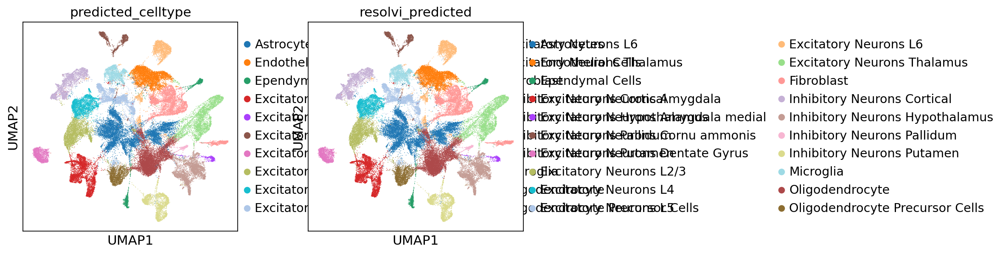

/tmp/ipykernel_3603058/2132712317.py:2: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(ref_adata, color=["predicted_celltype", "resolvi_predicted"], spot_size=30)


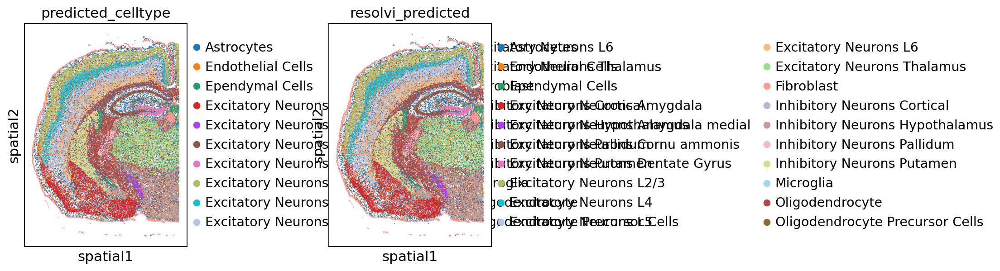

In [19]:
sc.pl.umap(ref_adata, color=["predicted_celltype", "resolvi_predicted"])
sc.pl.spatial(ref_adata, color=["predicted_celltype", "resolvi_predicted"], spot_size=30)

We can use the trained model to perform differential expression of two groups of cells. We compute here genes differentially expressed between neurons in two distinct layers. This uses a similar test to the scVI DE test. Please keep in mind this test doesn't test for differences in the mean between two groups but tests for differences between random pairs of single cell.

In [20]:
de_result_importance = supervised_resolvi.differential_expression(
    ref_adata,
    groupby="resolvi_predicted",
    group1="Excitatory Neurons L6",
    group2="Excitatory Neurons L5",
    weights="importance",
    pseudocounts=1e-2,
    delta=0.05,
    filter_outlier_cells=True,
    mode="change",
    test_mode="three",
)
de_result_importance.head(5)

DE...:   0%|          | 0/1 [00:00<?, ?it/s]

Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note th

,proba_de,proba_not_de,bayes_factor,scale1,scale2,pseudocounts,delta,lfc_mean,lfc_median,lfc_std,...,raw_mean1,raw_mean2,non_zeros_proportion1,non_zeros_proportion2,raw_normalized_mean1,raw_normalized_mean2,is_de_fdr_0.05,comparison,group1,group2
Nell1,0.9952,0.0048,5.334326,0.000641,0.006861,0.01,0.05,-3.385726,-3.441752,1.080262,...,0.324072,2.675077,0.239530,0.651579,10.816322,69.325653,True,Excitatory Neurons L6 vs Excitatory Neurons L5,Excitatory Neurons L6,Excitatory Neurons L5
Gadd45a,0.9950,0.0050,5.293303,0.018459,0.003499,0.01,0.05,2.513097,2.516529,0.911158,...,5.232484,1.187490,0.899413,0.518860,168.599197,32.589832,True,Excitatory Neurons L6 vs Excitatory Neurons L5,Excitatory Neurons L6,Excitatory Neurons L5
Tle4,0.9892,0.0108,4.517349,0.029843,0.006475,0.01,0.05,2.433442,2.504916,0.938781,...,7.880608,1.995275,0.981213,0.716681,258.182281,57.103371,True,Excitatory Neurons L6 vs Excitatory Neurons L5,Excitatory Neurons L6,Excitatory Neurons L5
Foxp2,0.9888,0.0112,4.480577,0.012506,0.001084,0.01,0.05,3.764901,3.846642,1.405026,...,3.185513,0.391448,0.812916,0.259290,102.060555,11.052588,True,Excitatory Neurons L6 vs Excitatory Neurons L5,Excitatory Neurons L6,Excitatory Neurons L5
Vat1l,0.9818,0.0182,3.987965,0.000550,0.004716,0.01,0.05,-3.025303,-2.947378,1.270591,...,0.219570,2.009240,0.164775,0.609668,7.076356,51.086510,True,Excitatory Neurons L6 vs Excitatory Neurons L5,Excitatory Neurons L6,Excitatory Neurons L5


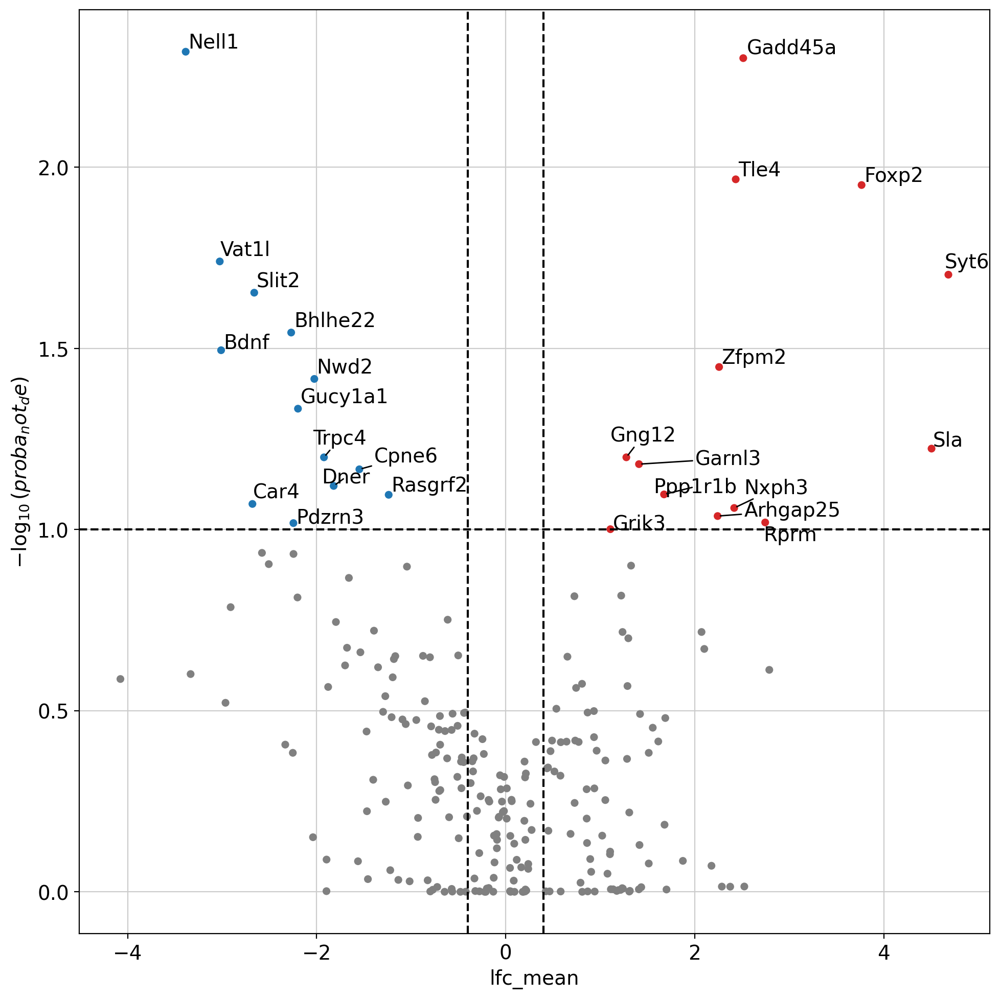

In [21]:
dc.pl.volcano(
    de_result_importance,
    x="lfc_mean",
    y="proba_not_de",
    thr_sign=0.1,
    thr_stat=0.4,
    top=30,
    figsize=(10, 10),
)
plt.show()

We can use the trained model to perform differential abundance of cell states in the neighborhood of two groups of cells. We find here that excitatory neurons in thalamus and cortex preferentially colocalize with themselves as well as adjacent layer neurons. This uses a similar test to the scVI DE test.

In [22]:
da = supervised_resolvi.differential_niche_abundance(
    groupby="resolvi_predicted",
    group1="Excitatory Neurons L4",
    group2="Excitatory Neurons Thalamus",
    neighbor_key="index_neighbor",
    test_mode="three",
    delta=0.05,
    pseudocounts=3e-2,
)
da.head(5)

DE...:   0%|          | 0/1 [00:00<?, ?it/s]

Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.


Sampling local variables, batch:   0%|          | 0/22 [00:00<?, ?it/s]

Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.


Sampling local variables, batch:   0%|          | 0/32 [00:00<?, ?it/s]

,proba_de,proba_not_de,bayes_factor,scale1,scale2,pseudocounts,delta,lfc_mean,lfc_median,lfc_std,lfc_min,lfc_max,is_de_fdr_0.05,comparison,group1,group2
Excitatory Neurons Thalamus,1.0000,0.0000,18.420681,0.001511,0.598973,0.03,0.05,-11.650728,-12.344234,2.418448,-14.928167,-1.892663,True,Excitatory Neurons L4 vs Excitatory Neurons Th...,Excitatory Neurons L4,Excitatory Neurons Thalamus
Excitatory Neurons L4,0.9994,0.0006,7.417964,0.582822,0.000679,0.03,0.05,12.008582,12.285867,1.591905,-0.208006,14.907028,True,Excitatory Neurons L4 vs Excitatory Neurons Th...,Excitatory Neurons L4,Excitatory Neurons Thalamus
Excitatory Neurons L2/3,0.8102,0.1898,1.451310,0.055099,0.000189,0.03,0.05,7.283712,7.174227,3.237767,-4.582611,14.729526,False,Excitatory Neurons L4 vs Excitatory Neurons Th...,Excitatory Neurons L4,Excitatory Neurons Thalamus
Oligodendrocyte,0.6322,0.3678,0.541666,0.019849,0.072914,0.03,0.05,-5.364277,-5.753439,6.008861,-14.168882,11.634401,False,Excitatory Neurons L4 vs Excitatory Neurons Th...,Excitatory Neurons L4,Excitatory Neurons Thalamus
Astrocytes,0.6022,0.3978,0.414640,0.077310,0.128933,0.03,0.05,-2.427101,-1.016521,5.737535,-13.963465,12.578515,False,Excitatory Neurons L4 vs Excitatory Neurons Th...,Excitatory Neurons L4,Excitatory Neurons Thalamus


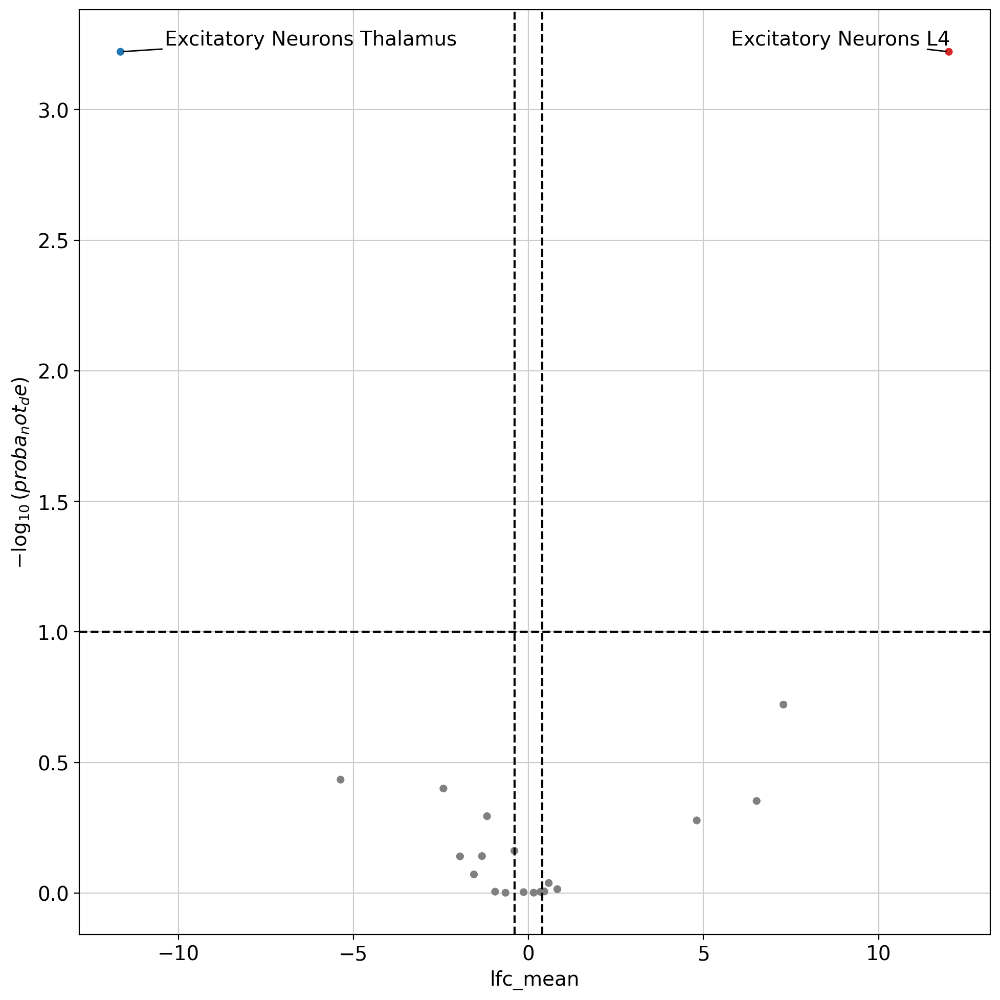

In [23]:
dc.pl.volcano(
    da,
    x="lfc_mean",
    y="proba_not_de",
    thr_sign=0.1,
    thr_stat=0.4,
    top=30,
    figsize=(10, 10),
)
plt.show()

We can also generate counts that are corrected for counts from neighboring cells wrongly assigned due to missegmentation as well as unspecific background. We use custom parameters for num_samples and and summary_fun to accelerate computation. "px_rate" of model_corrected generates corrected count data. "mixture_proportions" of model_residuals generates the amount of diffusion and background for each cell. Batch steps defines how many batches are accumulated before computing summary statistics.
To increase the amount of correction, use lower quantiles instead of median.

In [24]:
import pandas as pd

In [25]:
samples_corr = supervised_resolvi.sample_posterior(
    model=supervised_resolvi.module.model_corrected,
    return_sites=["px_rate"],
    summary_fun={"post_sample_q50": np.median},
    num_samples=3,
    summary_frequency=30,
)
samples_corr = pd.DataFrame(samples_corr).T

Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.


Sampling local variables, batch:   0%|          | 0/520 [00:00<?, ?it/s]

In [26]:
samples = supervised_resolvi.sample_posterior(
    model=supervised_resolvi.module.model_residuals,
    return_sites=["mixture_proportions"],
    summary_fun={"post_sample_means": np.mean},
    num_samples=3,
    summary_frequency=100,
)
samples = pd.DataFrame(samples).T

Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.


Sampling local variables, batch:   0%|          | 0/520 [00:00<?, ?it/s]

In [27]:
ref_adata.obs[["true_proportion", "diffusion_proportion", "background_proportion"]] = samples.loc[
    "post_sample_means", "mixture_proportions"
]

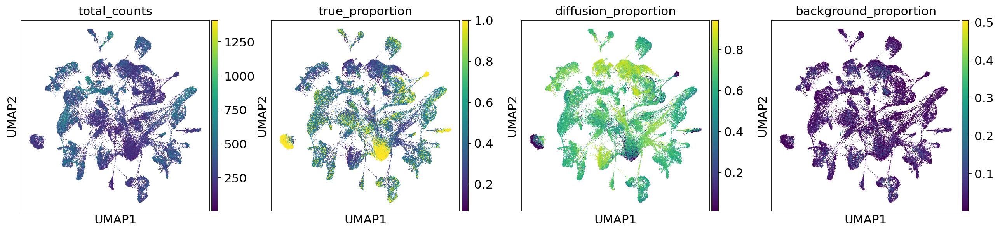

In [28]:
sc.pl.umap(
    ref_adata,
    color=["total_counts", "true_proportion", "diffusion_proportion", "background_proportion"],
)

In [29]:
ref_adata.layers["generated_expression"] = samples_corr.loc["post_sample_q50", "px_rate"]

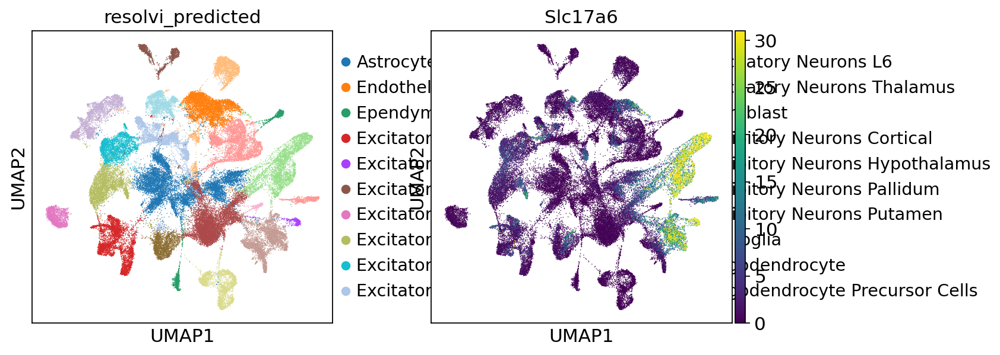

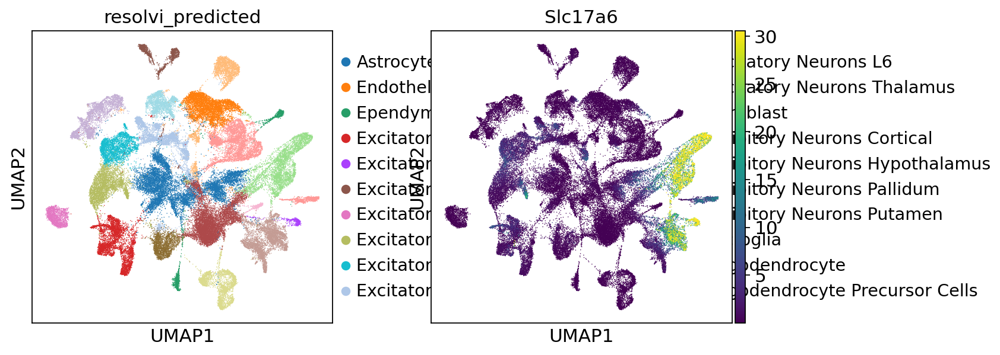

In [30]:
sc.pl.umap(ref_adata, color=["resolvi_predicted", "Slc17a6"], layer="counts", vmax="p98")
sc.pl.umap(
    ref_adata, color=["resolvi_predicted", "Slc17a6"], layer="generated_expression", vmax="p98"
)

## Query transfer
We can train the reference model on query data to reannotate this data. We rely on the observation names for non-amortized parameters in resolVI. It is important to make sure cells have unique names between query and reference dataset. We set the cell-type to unknown, so that resolVI needs to predict the celltype leveraging the reference model.

In [31]:
query_adata.obs["predicted_celltype"] = "unknown"
query_adata.obs_names = [f"query_{i}" for i in query_adata.obs_names]

In [32]:
supervised_resolvi.prepare_query_anndata(query_adata, reference_model=supervised_resolvi)
query_resolvi = supervised_resolvi.load_query_data(query_adata, reference_model=supervised_resolvi)

INFO     Found 100.0% reference vars in query data.                                                                


Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.


Preparing data for training. This may take a while. RAPIDS SingleCell will be used if installed.


/home/access/PycharmProjects/scvi-tools/src/scvi/data/fields/_dataframe_field.py:233: UserWarning: Category 66457 in adata.obs['_scvi_ind_x'] has fewer than 3 cells. Models may not train properly.
  new_mapping = _make_column_categorical(


In [33]:
query_resolvi.train(max_epochs=20)

Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/home/access/miniconda3/lib/python3.13/site-packages/lightning/pytorch/trainer/configuration_validator.py:68: You passed in a `val_dataloader` but have no `validation_step`. Skipping val loop.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]


Running transfer learning mode. Set lr to 0 and blocking variables.


/home/access/miniconda3/lib/python3.13/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/home/access/miniconda3/lib/python3.13/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=63` in the `DataLoader` to improve performance.
/home/access/miniconda3/lib/python3.13/site-packages/lightning/pytorch/loops/fit_loop.py:538: Found 52 module(s) in eval mode at the start of training. This may lead to unexpected behavior during training. If this is intentional, you can ignore this warning.


Training:   0%|          | 0/20 [00:00<?, ?it/s]

2026-11-16 10:35:39 | [INFO] Guessed max_plate_nesting = 2
`Trainer.fit` stopped: `max_epochs=20` reached.


In [34]:
query_adata.obs["resolvi_predicted"] = query_resolvi.predict(
    query_adata, num_samples=3, soft=False
)
query_adata.obsm["X_resolVI"] = query_resolvi.get_latent_representation(query_adata)

Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.


Sampling local variables, batch:   0%|          | 0/129 [00:00<?, ?it/s]

Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.


Again, we may visualize the latent space as well as the inferred labels

In [35]:
if HAS_RSC:
    rsc.pp.neighbors(query_adata, use_rep="X_resolVI")
    rsc.tl.umap(query_adata)
else:
    sc.pp.neighbors(query_adata, use_rep="X_resolVI")
    sc.tl.umap(query_adata)

... storing 'predicted_celltype' as categorical
... storing 'resolvi_predicted' as categorical


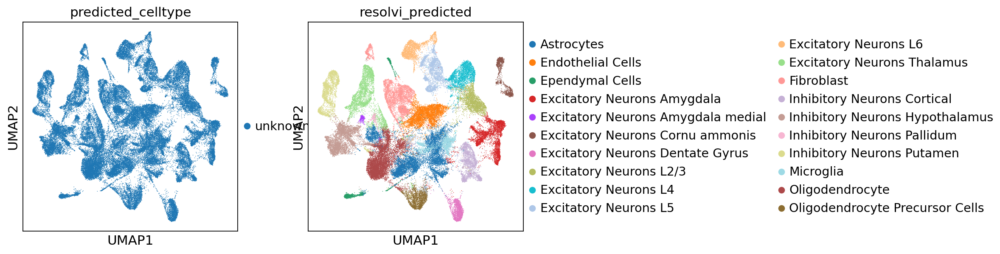

/tmp/ipykernel_3603058/1669651559.py:2: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(query_adata, color=["predicted_celltype", "resolvi_predicted"], spot_size=30)


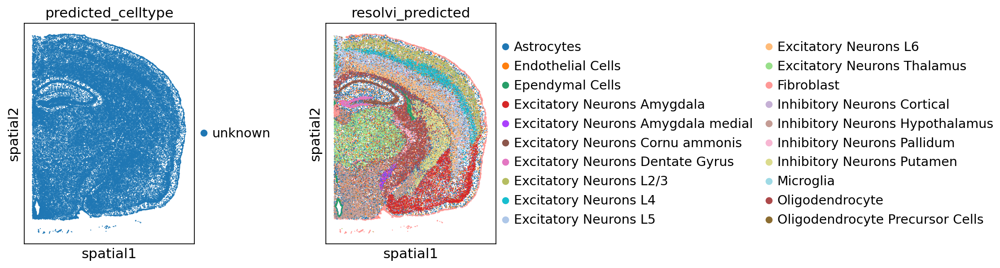

In [36]:
sc.pl.umap(query_adata, color=["predicted_celltype", "resolvi_predicted"])
sc.pl.spatial(query_adata, color=["predicted_celltype", "resolvi_predicted"], spot_size=30)

We can now concatenate the datasets again and find good integration and accurate cell-type information.

In [41]:
import anndata as ad
full_adata = ad.concat(                                                                                                                                                                      
    {"reference": ref_adata, "query": query_adata},                                                                                                                                          
    label="source",                                                                                                                                                                          
    index_unique="-",                                                                                                                                                                        
    merge="same",                                                                                                                                                                            
)  

In [42]:
if HAS_RSC:
    rsc.pp.neighbors(full_adata, use_rep="X_resolVI")
    rsc.tl.umap(full_adata)
else:
    sc.pp.neighbors(full_adata, use_rep="X_resolVI")
    sc.tl.umap(full_adata)

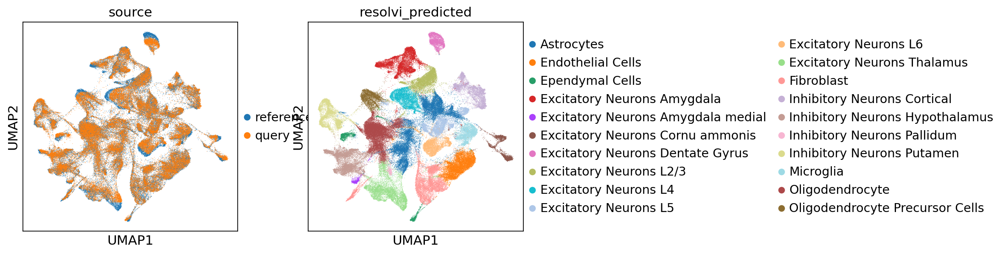

/tmp/ipykernel_3603058/3452622550.py:2: FutureWarning: The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(full_adata, color=["source", "resolvi_predicted"], spot_size=30)


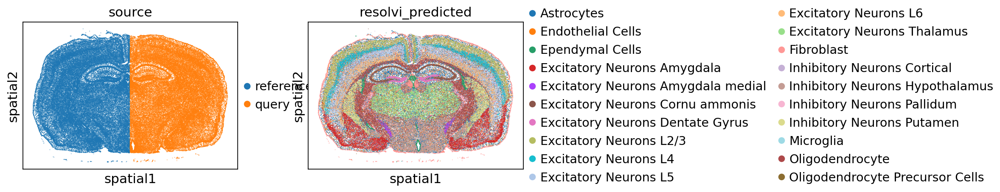

In [43]:
sc.pl.umap(full_adata, color=["source", "resolvi_predicted"])
sc.pl.spatial(full_adata, color=["source", "resolvi_predicted"], spot_size=30)

## Benchmarking latent spaces with scib-metrics

We compare the resolVI latent space (`X_resolVI`) against two baselines using [scib-metrics](https://scib-metrics.readthedocs.io):

- **PCA** on log-normalized counts: an unintegrated baseline.
- **scVI**: a non-spatial deep generative model with `source` (reference vs. query hemisphere) as batch covariate.

Bio-conservation metrics are computed against the ground-truth labels (the ProSeg-derived `predicted_celltype`). Batch-correction metrics measure how well the reference and query hemispheres mix. We don't benchmark the other `obsm` entries: `X_spatial` holds coordinates, `X_umap*` are 2D visualizations, and `index_neighbor`/`distance_neighbor` are neighbor graphs, not embeddings.

PCA and scVI are fit on the full dataset, like resolVI. Only the metric computation, which scales poorly with cell count, runs on a random subsample of `N_CELLS` cells. Increase it once the runtime is acceptable.

In [46]:
from scib_metrics.benchmark import BatchCorrection, Benchmarker, BioConservation

# Query labels were masked as "unknown" before query mapping, so recover the ground truth.
expected_names = np.concatenate(
    [ref_adata.obs_names + "-reference", query_adata.obs_names + "-query"]
)
assert (full_adata.obs_names == expected_names).all()
full_adata.obs["celltype_true"] = pd.Categorical(
    np.concatenate(
        [
            ref_adata.obs["predicted_celltype"].astype(str).to_numpy(),
            adata.obs.loc[adata.obs["hemisphere"] == "right", "predicted_celltype"]
            .astype(str)
            .to_numpy(),
        ]
    )
)

Compute the PCA baseline on log-normalized counts of the full dataset.

In [ ]:
full_adata.X = full_adata.layers["counts"].copy()
sc.pp.normalize_total(full_adata)
sc.pp.log1p(full_adata)
sc.pp.pca(full_adata, n_comps=30)

Train scVI on the full dataset with `source` as batch covariate.

In [ ]:
scvi.model.SCVI.setup_anndata(full_adata, layer="counts", batch_key="source")
scvi_model = scvi.model.SCVI(full_adata, n_latent=10)
scvi_model.train(max_epochs=100)
full_adata.obsm["X_scVI"] = scvi_model.get_latent_representation()

Subsample cells for the metric computation only.

In [47]:
N_CELLS = 10_000  # increase once runtime is acceptable

# Keep cell types present in both hemispheres; batch metrics like BRAS need >1 batch per label.
shared = set(full_adata.obs.loc[full_adata.obs["source"] == "reference", "celltype_true"]) & set(
    full_adata.obs.loc[full_adata.obs["source"] == "query", "celltype_true"]
)
bench_adata = full_adata[full_adata.obs["celltype_true"].isin(shared)]

rng = np.random.default_rng(0)
idx = rng.choice(bench_adata.n_obs, size=min(N_CELLS, bench_adata.n_obs), replace=False)
bench_adata = bench_adata[np.sort(idx)].copy()
bench_adata.obs["celltype_true"] = bench_adata.obs["celltype_true"].cat.remove_unused_categories()
bench_adata.obs["source"].value_counts()

source
reference    5069
query        4931
Name: count, dtype: int64

In [50]:
bm = Benchmarker(
    bench_adata,
    batch_key="source",
    label_key="celltype_true",
    embedding_obsm_keys=["X_pca", "X_scVI", "X_resolVI"],
    pre_integrated_embedding_obsm_key="X_pca",
    bio_conservation_metrics=BioConservation(),
    batch_correction_metrics=BatchCorrection(),
    n_jobs=-1,
    solver="full",  # "arpack" fails with cuML PCA when rapids_singlecell is installed
)
bm.benchmark()

Metrics:   0%|                                                            | 0/11 [00:00<?, ?it/s, Bio conservation: isolated_labels]2026-11-16 11:22:35 | [INFO] isolated labels: no more than 2 batches per label
2026-11-16 11:22:35 | [INFO] Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
E1116 11:24:35.718527 3614058 slow_operation_alarm.cc:73] 
********************************
[Compiling module loop_reduce_fusion for GPU] Very slow compile? If you want to file a bug, run with envvar XLA_FLAGS=--xla_dump_to=/tmp/foo and attach the results.
********************************
E1116 11:25:44.138092 3614055 slow_operation_alarm.cc:140] The operation took 3m8.419638269s

********************************
[Compiling module loop_reduce_fusion for GPU] Very slow compile? If you want to file a bug, run with envvar XLA_FLAGS=--xla_dump_to=/tmp/foo and attach the results.
********************************

Emb

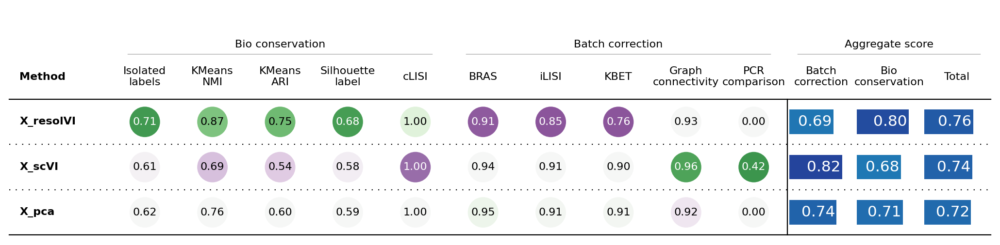

In [51]:
bm.plot_results_table(min_max_scale=False)

In [53]:
import gc

gc.collect()
import torch

torch.cuda.empty_cache()